In [20]:
import time
import h5py

import numpy as np
import matplotlib as mpl
import matplotlib.pyplot as plt
import sys
import scipy.stats as st

from chemrixs.average import Average
from chemrixs.smalldata import SmallData
from chemrixs.process import Reduced
from chemrixs.utils import *
from pathlib import Path
from scipy.ndimage._filters import uniform_filter1d as uf
%matplotlib widget 

<KeysViewHDF5 ['lxt_ttc', 'step_value']>
71
setting up properties
dataset prop <functools.cached_property object at 0x7fe8ce251210>
dataset prop <functools.cached_property object at 0x7fe8c504cc50>
dataset prop <functools.cached_property object at 0x7fe8cd216c90>
dataset prop <functools.cached_property object at 0x7fe8c50692d0>
dataset prop <functools.cached_property object at 0x7fe8ce2ffed0>
dataset prop <functools.cached_property object at 0x7fe8c504dbd0>
dataset prop <functools.cached_property object at 0x7fe8cd239a10>
dataset prop <functools.cached_property object at 0x7fe8c5119ad0>
delay shape (7389,)
61
setting up properties
dataset prop <functools.cached_property object at 0x7fe8cd1ff610>
dataset prop <functools.cached_property object at 0x7fe8ce25dd50>
dataset prop <functools.cached_property object at 0x7fe8c5141090>
dataset prop <functools.cached_property object at 0x7fe8cd21b810>
dataset prop <functools.cached_property object at 0x7fe8c5142010>
dataset prop <functools.cached_

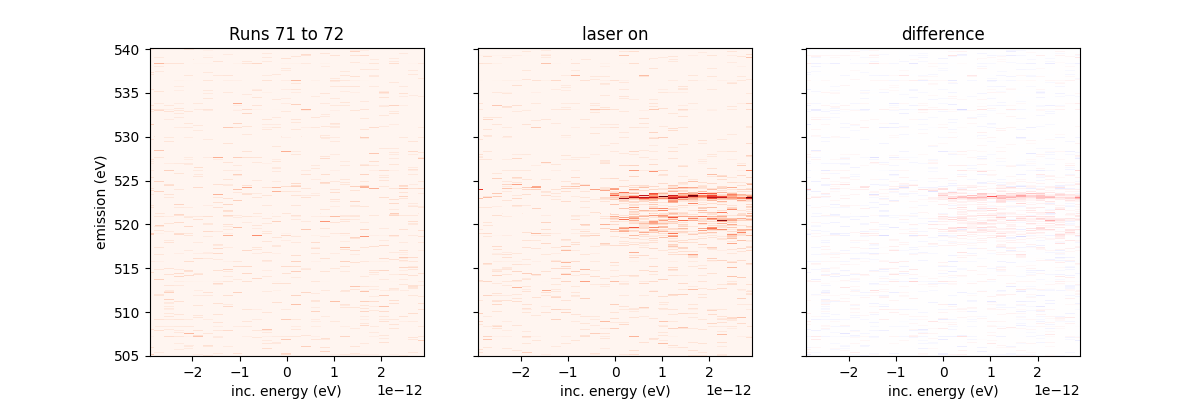

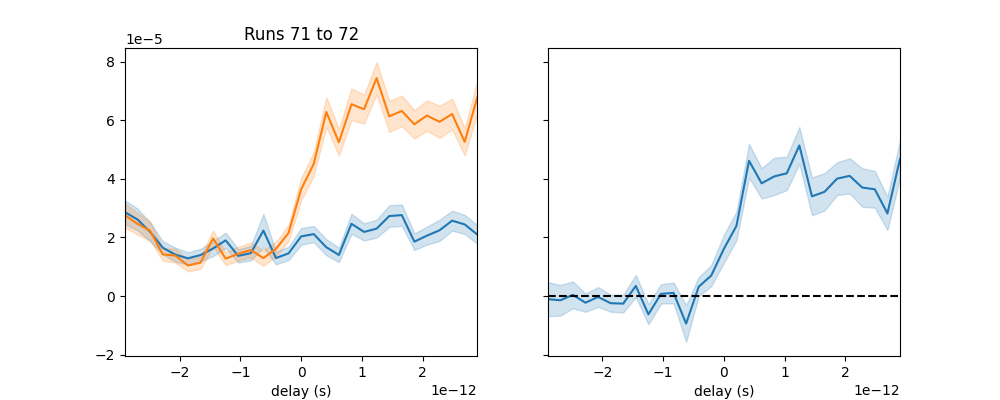

In [3]:
import h5py, numpy as np, scipy.stats as st
import matplotlib.pyplot as plt

base_folder =  '/sdf/data/lcls/ds/rix/'
exp = 'rix101231825'
run = 61
f = h5py.File(f'{base_folder}/{exp}/hdf5/smalldata/{exp}_Run{run:04d}.h5','r'); g='intg/axis_svls/'
cnt  = np.asarray(f[g+'count']).squeeze()
evc  = np.asarray(f[g+'timing_sum_eventcodes'])
sm   = np.asarray(f[g+'scan_sum_lxt_ttc']).squeeze()
svls = np.asarray(f[g+'droplet_dense_curve_corr_pj_ax_1_data'])
mode = st.mode(cnt, keepdims=False)[0]
svls = np.where((svls<0)|(svls>5000)|np.isnan(svls), 0, svls); pfy = svls.sum(1)
delay = sm/mode
edges = np.linspace(-2e-12,5e-12,24); cen = 0.5*(edges[1:]+edges[:-1])
def bm(x,y,e):
    i = np.digitize(x,e)
    return np.array([np.nanmean(y[i==k]) if np.any(i==k) else np.nan for k in range(1,len(e))])
def transient(sel):
    on  = sel & (evc[:,272]/mode > 0.5)
    off = sel & (evc[:,273]/mode > 0.5)
    return bm(delay[on],pfy[on],edges) - bm(delay[off],pfy[off],edges), int(on.sum()), int(off.sum())

fig,ax = plt.subplots(1,3,figsize=(15,4),sharex=True,sharey=True)
for a,(label,sel) in zip(ax, [('count=335', cnt==335),
                              ('count=336', cnt==336),
                              ('335+336  (= ±2)', (cnt==335)|(cnt==336))]):
    d,non,noff = transient(sel)
    a.plot(cen*1e12, d); a.axhline(0,ls='--',c='k')
    a.set_title(f'{label}  (on={non}, off={noff})'); a.set_xlabel('delay (ps)')
ax[0].set_ylabel('PFY on-off (raw)')
plt.tight_layout(); plt.show()
f.close()

In [19]:
import h5py, numpy as np, scipy.stats as st
runs = [65]
PFYon=[];PFYoff=[];Don=[];Doff=[];I0on=[];I0off=[]
for run in runs:
    f=h5py.File(f'{base_folder}/{exp}/hdf5/smalldata/{exp}_Run{run:04d}.h5','r'); g='intg/axis_svls/'
    cnt=np.asarray(f[g+'count']).squeeze(); evc=np.asarray(f[g+'timing_sum_eventcodes'])
    sm=np.asarray(f[g+'scan_sum_lxt_ttc']).squeeze()
    svls=np.asarray(f[g+'droplet_dense_curve_corr_pj_ax_1_data'])
    pir=np.asarray(f[g+'c_piranha_sum_full_area']); mode=st.mode(cnt,keepdims=False)[0]
    svls=np.where((svls<0)|(svls>5000)|np.isnan(svls),0,svls); pfy=svls.sum(1)
    I0=pir[:,1000:1150].sum(1).astype(float); delay=sm/mode
    sel=(cnt==mode); on=sel&(evc[:,272]/mode>0.5); off=sel&(evc[:,273]/mode>0.5)
    PFYon.append(pfy[on]);PFYoff.append(pfy[off]);Don.append(delay[on]);Doff.append(delay[off])
    I0on.append(I0[on]);I0off.append(I0[off]); f.close()
PFYon,PFYoff=np.concatenate(PFYon),np.concatenate(PFYoff)
Don,Doff=np.concatenate(Don),np.concatenate(Doff)
I0on,I0off=np.concatenate(I0on),np.concatenate(I0off)

print('I0(beam) on/off ratio: %.4f  (1.0 = clean; != 1 means I0 carries a laser signal)'
      % (np.nanmean(I0on)/np.nanmean(I0off)))

def m(D,Y,lo,hi):
    s=(D>lo)&(D<hi); return np.nanmean(Y[s]), np.nanstd(Y[s])/np.sqrt(s.sum())
opre,eopre=m(Don,PFYon,-2e-12,-0.3e-12); fpre,efpre=m(Doff,PFYoff,-2e-12,-0.3e-12)
opost,eopost=m(Don,PFYon,0.3e-12,5e-12); fpost,efpost=m(Doff,PFYoff,0.3e-12,5e-12)
dpre,edpre=opre-fpre,np.hypot(eopre,efpre); dpost,edpost=opost-fpost,np.hypot(eopost,efpost)
print('on-off  pre-t0 : %+.1f ± %.1f' % (dpre,edpre))
print('on-off post-t0 : %+.1f ± %.1f' % (dpost,edpost))
print('post - pre     : %+.1f ± %.1f  (%.1f sigma)'
      % (dpost-dpre, np.hypot(edpre,edpost), (dpost-dpre)/np.hypot(edpre,edpost)))

I0(beam) on/off ratio: 1.0056  (1.0 = clean; != 1 means I0 carries a laser signal)
on-off  pre-t0 : -32.7 ± 53.0
on-off post-t0 : +68.7 ± 33.4
post - pre     : +101.4 ± 62.7  (1.6 sigma)


## Load and plot the data first to see how the data looks

In in the yaml file you need to change the 'TT_corr: {bool: True, offset: 1100}' bool to False if you haven't created the file with TT correction yet

<KeysViewHDF5 ['lxt_ttc', 'step_value']>
58
setting up properties
dataset prop <functools.cached_property object at 0x7fdcf7de62d0>
dataset prop <functools.cached_property object at 0x7fdcfb29c550>
dataset prop <functools.cached_property object at 0x7fdcf98d3a50>
dataset prop <functools.cached_property object at 0x7fdcf7c260d0>
dataset prop <functools.cached_property object at 0x7fdcf98a2550>
dataset prop <functools.cached_property object at 0x7fdcf7de1350>
dataset prop <functools.cached_property object at 0x7fdcf7c024d0>
dataset prop <functools.cached_property object at 0x7fdcf7ef04d0>
dataset prop <functools.cached_property object at 0x7fdcf9742dd0>
delay shape (13816,)


86
setting up properties
dataset prop <functools.cached_property object at 0x7fdcf7db71d0>
dataset prop <functools.cached_property object at 0x7fdcf9727d50>
dataset prop <functools.cached_property object at 0x7fdcf9840750>
dataset prop <functools.cached_property object at 0x7fdcf7c14590>
dataset prop <functools.cached_property object at 0x7fdcf7dd40d0>
dataset prop <functools.cached_property object at 0x7fdcf7d63a90>
scanvariable is unkown, binning not possible
delay_fly
fly scan!
uncorrected delay
fly)
bin_edges
fly)
bin_edges
fly)
bin_edges
fly)
bin_edges
fly)
bin_edges
fly)
bin_edges
saving data
saved processed data
[ 0. 63. 63. 63. 63. 63. 63. 64. 63. 64. 64. 65. 65. 64. 65. 64. 65. 64.
 64. 64. 64. 63. 63. 63. 63. 63. 63. 63. 63. 63. 63. 63. 63. 63. 63. 63.
 63. 63. 63. 63. 63. 63. 63. 63. 63. 63. 63.]
  despeckle [axis_svls_off_mean]: kernel=3, n_sigma=10 -> flagged 25 pixels (0.067%)
  despeckle [axis_svls_on_mean]: kernel=3, n_sigma=10 -> flagged 28 pixels (0.075%)
  despeckle 

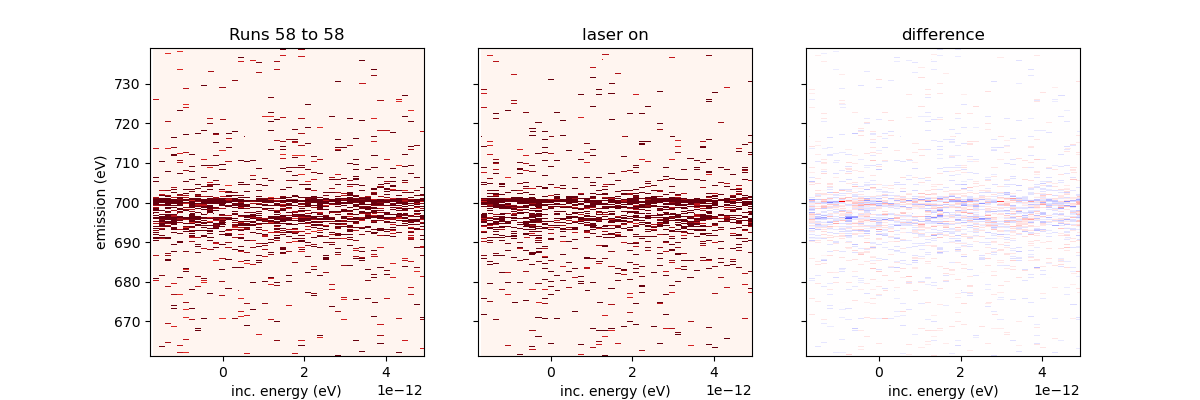

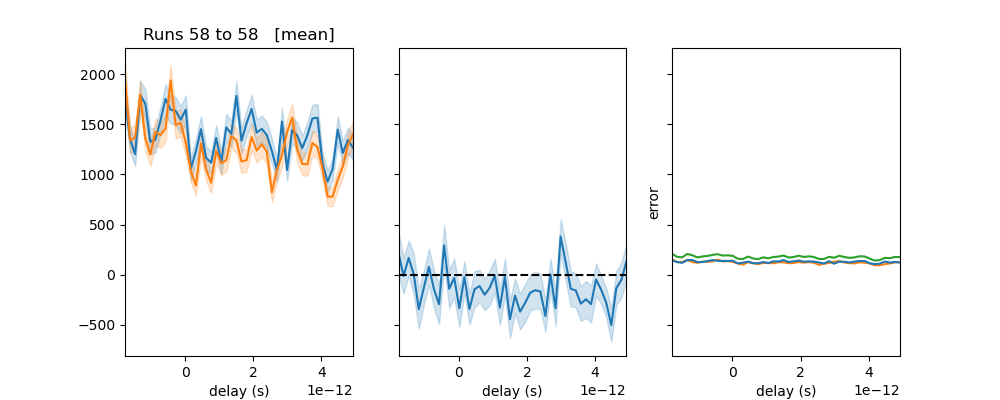

In [ ]:
#############single shot data - run 69,112


base_folder =  '/sdf/data/lcls/ds/rix/'
proc_folder = './proc/'

bgrun = 61
runs=[71,72] # O K-edge A peak time trace
# runs=[84,86,87,88,89,90,91,92,93,94,95,96,97,98,99,102,103,104] # O K-edge B peak time trace
# runs=[7]#[166,167,168,169,170,171,172,173,174,175,176,177,178,180,181,182,183,184,187,188,189,190,191,192,193,195,196,197,198,199,200] # N K-edge B peak time trace

# runs = [200]

runs = [61,62,63,64,65,66,67,68,69]
# runs = [157]
exp = 'rix101231825'
# runs = [114]
# runs = [61,62,63,64,66]
# runs = [68]
# runs = [66]
# runs = [162,163,164,165,166,167,168,169]
# runs = [113]
runs = [58]
# fyaml = '../roi_inputTT.yml'
fyaml = '../roi_input.yml'
bgname = f'{base_folder}/{exp}/hdf5/smalldata/{exp}_Run{bgrun:04d}.h5'
bgyaml = '../BGroi_input.yml'

avg = Average(runs, proc_path = 'proc/Run', avg = 'mean', output_path = f'avg/{runs[0]}_to_{runs[-1]}.h5',
             raw_path = f'{base_folder}/{exp}/hdf5/smalldata/{exp}_Run' , bgpath = bgname, fyaml=fyaml, bgyaml=bgyaml, 
             save= False,norm = True)

avg.plot_svls2D(figsize=(12,4),savefig=False,scale=10)

avg.plot_svls1D(figsize=(10,4),savefig=False)

avg.save_avg()
# 

In [4]:
with h5py.File(f'{base_folder}/{exp}/hdf5/smalldata/{exp}_Run0061.h5','r') as f:
    print([k for k in f['intg/axis_svls'].keys() if 'lxt' in k or 'delay' in k])

['scan_sum_lxt_ttc']


In [32]:
E = avg.average['E_emi']
emi_lo, emi_hi = sorted([np.argmin(np.abs(E-698)), np.argmin(np.abs(E-702))])

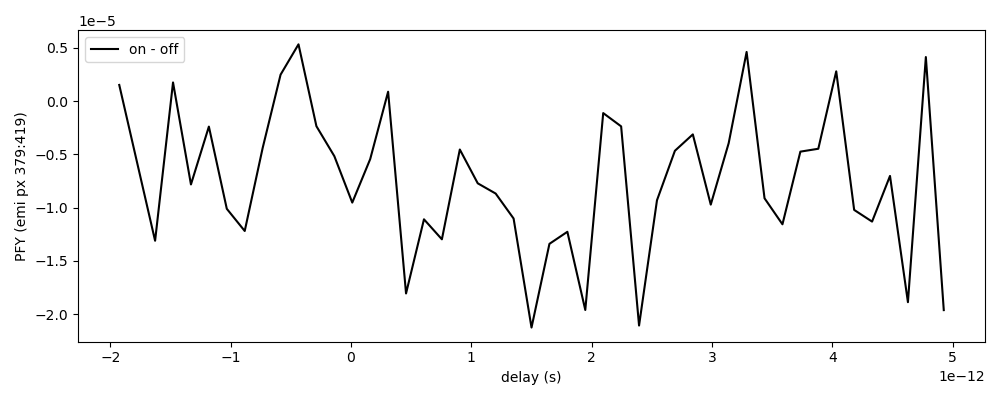

In [33]:
# emi_lo, emi_hi = 698, 702        # emission pixel range to sum (check avg.average['axis_svls_on_mean'].shape[1])

on   = avg.average['axis_svls_on_mean']
off  = avg.average['axis_svls_off_mean']
x_on  = avg.average['scanvar_on']
x_off = avg.average['scanvar_off']

pfy_on  = np.nansum(on[:,  emi_lo:emi_hi], axis=1)
pfy_off = np.nansum(off[:, emi_lo:emi_hi], axis=1)

plt.figure(figsize=(10,4))
# plt.plot(x_off, pfy_off, label='off')
# plt.plot(x_on,  pfy_on,  label='on')
plt.plot(x_on,  pfy_on - pfy_off, 'k', label='on - off')
plt.xlabel('delay (s)')
plt.ylabel(f'PFY (emi px {emi_lo}:{emi_hi})')
plt.legend(); plt.tight_layout(); plt.show()

In [5]:
# proc = Reduced(fname,bgname,fyaml,bgyaml)

# expected_count = st.mode(proc.data.integrating.axis_svls.count, keepdims=False)[0]
# mask1 = (proc.data.integrating.axis_svls.eventcodes[:,proc.data.yaml['evc'][True]]/proc.data.integrating.axis_svls.count) >0.5

# mask2= (proc.data.integrating.axis_svls.eventcodes[:,proc.data.yaml['evc'][True]]/expected_count)>0.5
# # np.sum(mask1==mask2)
# # proc.data.scantype

<KeysViewHDF5 ['lxt_ttc', 'step_value']>
71
setting up properties
dataset prop <functools.cached_property object at 0x7f3ec73d5c90>
dataset prop <functools.cached_property object at 0x7f3ec734a090>
dataset prop <functools.cached_property object at 0x7f3ec7353490>
dataset prop <functools.cached_property object at 0x7f3ec73304d0>
dataset prop <functools.cached_property object at 0x7f3ec73f4250>
dataset prop <functools.cached_property object at 0x7f3ec73c7c10>
dataset prop <functools.cached_property object at 0x7f3ec73c68d0>
dataset prop <functools.cached_property object at 0x7f3ec7320410>
delay shape (7389,)
61
setting up properties
dataset prop <functools.cached_property object at 0x7f3ec73cf350>
dataset prop <functools.cached_property object at 0x7f3ec73b38d0>
dataset prop <functools.cached_property object at 0x7f3ec5a07a10>
dataset prop <functools.cached_property object at 0x7f3ec73e69d0>
dataset prop <functools.cached_property object at 0x7f3ec73e7290>
dataset prop <functools.cached_

### Plotting how the nominal delays during the experiment

Just a sanity check

Text(0.5, 0, 'frame #')

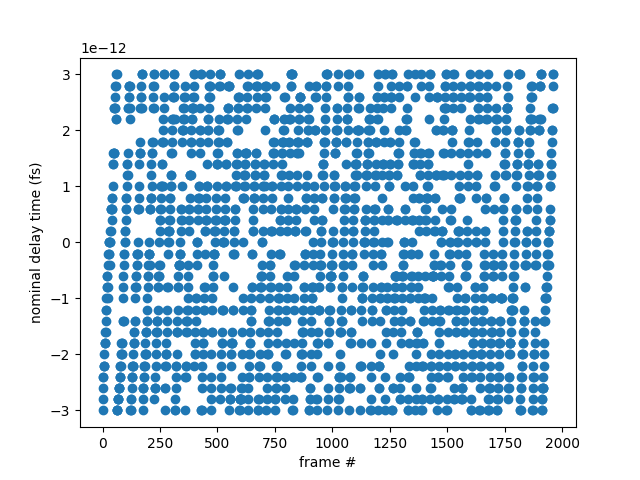

In [6]:
fig,ax=plt.subplots(1,1)
ax.scatter(np.arange(len(proc.data.integrating.axis_svls.delay[mask1])), proc.data.integrating.axis_svls.delay[mask1])
ax.set_ylabel('nominal delay time (fs)')
ax.set_xlabel('frame #')

## Load Piranha

- Loading the piranha data and creating masks for the on and off signal

- Plotting the averaged piranha signals

(0.0, 2000.0)

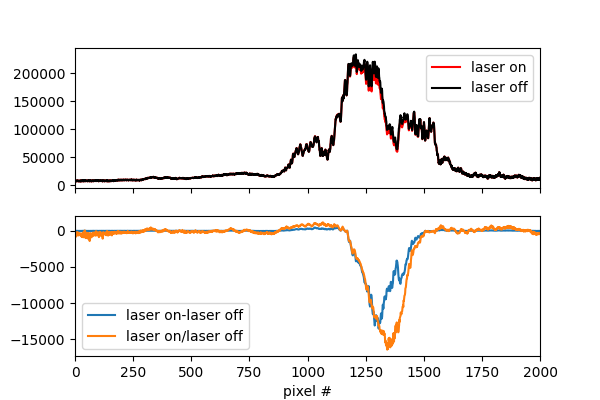

In [8]:

# expected_count = st.mode(proc.data.integrating.axis_svls.count, keepdims=False)[0]

# data.integrating.axis_svls.piranha.shape
# mask_on = ((proc.data.integrating.axis_svls.eventcodes[:,proc.data.yaml['evc'][True]]/proc.data.integrating.axis_svls.count) >0.5).squeeze()# (data.integrating.axis_svls.eventcodes[:,272]==1)# np.asarray([data.integrating.axis_svls.eventcodes[:,data.yaml['evc'][True]]/expected_count>0.5]).squeeze()
# mask_off = ((proc.data.integrating.axis_svls.eventcodes[:,proc.data.yaml['evc'][False]]/proc.data.integrating.axis_svls.count) >0.5).squeeze() #(data.integrating.axis_svls.eventcodes[:,273]==1)#

# piranha = (proc.data.integrating.axis_svls.piranha)
# piranha_on = (proc.data.integrating.axis_svls.piranha[mask_on,:])
# piranha_off =(proc.data.integrating.axis_svls.piranha[mask_off,:])

fig,ax=plt.subplots(2,1,figsize=(6,4),sharex=True)
ax[0].plot(np.nanmean(piranha_on,axis=0).T, 'r',label='laser on')
ax[0].plot(np.nanmean(piranha_off,axis=0).T, 'k',label='laser off')
ax[0].legend()
ax[1].plot((np.nanmean(piranha_on,axis=0))-(np.mean(piranha_off,axis=0)),label='laser on-laser off')
ax[1].plot(((np.nanmean(piranha_on,axis=0))/(np.mean(piranha_off,axis=0))-1)*2e5,label='laser on/laser off')
ax[1].legend()
ax[1].set_xlabel('pixel #')
ax[1].set_xlim(0,2000)

- plot individual piranha traces: it becomes visible how much the signal intensity fluctuates, we will deal with some background subtraction below to deal with this

Text(0.5, 0, 'pixel #')

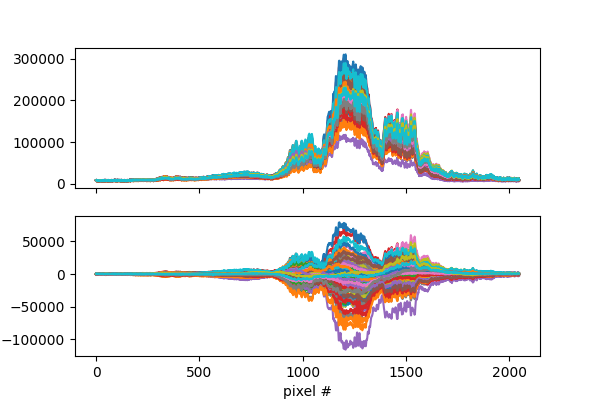

In [9]:
fig,ax=plt.subplots(2,1,figsize=(6,4),sharex=True)
ax[0].plot((piranha_on).T[:,:100],label='laser on')
# ax[0].plot(np.nanmean(piranha_off,axis=0).T, 'k',label='laser off')
ax[1].plot(((piranha_on.T[:,:100]))-(np.mean(piranha_off,axis=0))[:,np.newaxis],label='laser on-laser off')
ax[1].set_xlabel('pixel #')


In [ ]:
# import h5py, numpy as np
# fh = h5py.File(fname, 'r')

# raw_pir = np.array(fh['intg/axis_svls/c_piranha_sum_full_area'])
# tt_pir  = np.asarray(proc.data.integrating.axis_svls.piranha)

# print('shapes      :', raw_pir.shape, tt_pir.shape)
# print('identical?  :', np.array_equal(raw_pir, tt_pir))
# if raw_pir.shape == tt_pir.shape:
#     print('max abs diff:', np.abs(raw_pir.astype(float) - tt_pir.astype(float)).max())
#     print('raw[0,:5]   :', raw_pir[0, :5])
#     print('tt [0,:5]   :', tt_pir[0, :5])

# # and the inputs to the masks:
# print('evc same?   :', np.array_equal(np.array(fh['intg/axis_svls/timing_sum_eventcodes']),
#                                        np.asarray(proc.data.integrating.axis_svls.eventcodes)))
# print('count same? :', np.array_equal(np.array(fh['intg/axis_svls/count']),
#                                        np.asarray(proc.data.integrating.axis_svls.count)))

shapes      : (28909, 2048) (28909, 2048)
identical?  : True
max abs diff: 0.0
raw[0,:5]   : [8457 9186 8535 8609 7383]
tt [0,:5]   : [8457 9186 8535 8609 7383]
evc same?   : True
count same? : True


### Do SVD

- Use the plot above of the averaged data of laser on/laser off to determine the ROI (range where the peak is located), the analysis is very sensitive to the ROI, so you may need to play around with it

-  we do the decomposition with a subset of the dark data (N is number of traces), using a larger N will slow down the code quite significantly and I have not seen a visible improvement for the data 

- the last line then does the background subtraction based on the background decomposition, you can choose the number of components (neigs) to use. the analysis below is based on 'traces'

In [10]:
max_p = -1
ROI=[1100,1400]
N = 2000
# N = piranha_off.shape[0] 
v, s = decomp_((piranha_off[:,:])[:,:],N) #decomposition of BG data (dark)
traces = decomp_1d(v,s,piranha[:,:],ROI,neigs=2) #decompose all data only using an ROI

Now we are plotting the cleaned up piranha traces, you should see a strong negative signal



When we start seeing detector damages, instead of a somewhat Gaussian shape, you will see areas where it looks like something got simply got cut out of the Gaussian

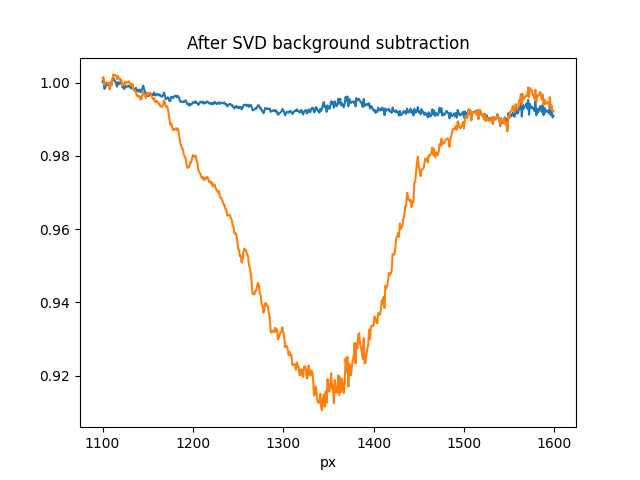

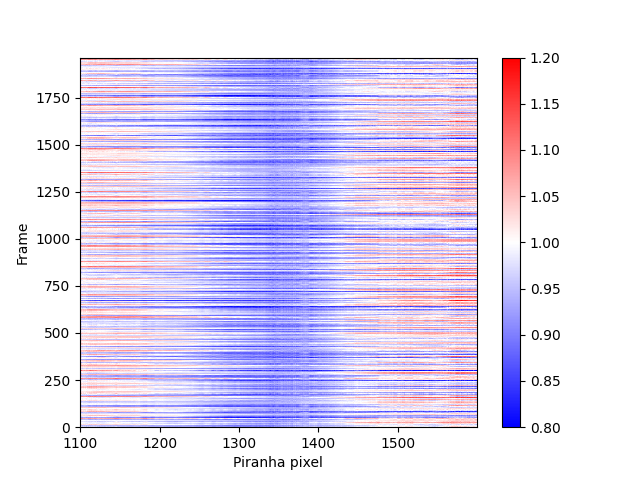

In [11]:

# traces_norm = traces/np.nansum(traces,axis = 1)[:,np.newaxis]

px = np.arange(ROI[0],ROI[1])
plt.figure()
plt.plot(px,np.nanmean(traces[mask_off[:],:],axis =0),label = 'Background')
plt.plot(px,np.nanmean(traces[mask_on[:],:],axis =0),label = 'Signal')
plt.title('After SVD background subtraction')
plt.xlabel('px')
plt.show()
plt.figure()
shots = np.arange(len(traces[mask_on[:]]))
plt.pcolormesh(px,np.arange(traces[mask_on[:]].shape[0]),traces[mask_on[:]],cmap = 'bwr',vmin = 0.96,vmax = 1.04)
# plt.pcolormesh(traces_norm[mask_on],cmap = 'bwr',vmin = 0.0023,vmax = 0.004)
plt.xlabel('Piranha pixel')
plt.ylabel('Frame')
plt.colorbar()
plt.show()



Text(0.5, 0, 'on-shot fraction per frame')

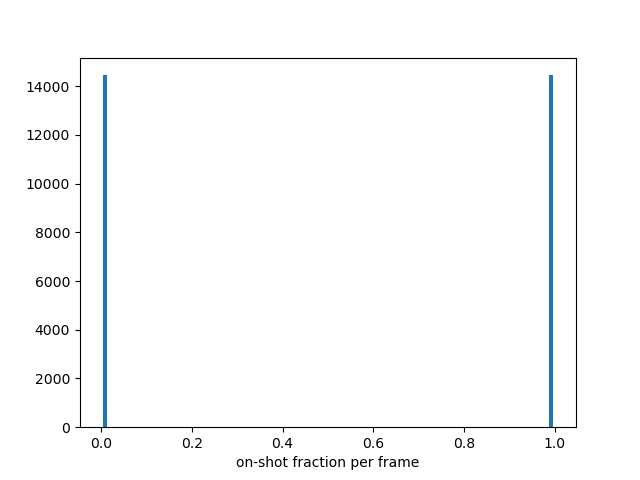

In [42]:
frac = (proc.data.integrating.axis_svls.eventcodes[:, proc.data.yaml['evc'][True]]
        / proc.data.integrating.axis_svls.count)
plt.figure()
plt.hist(frac, bins=100); plt.xlabel('on-shot fraction per frame')

This was just a test to see if it would be easier to look at the differential for finding the edge, the fitting analysis below seems to be more robust

In [12]:


# ds=uf(np.diff(uf(traces[mask_on[:]],size=1,axis=1,mode='nearest'),axis=1),size=10,axis=1,mode='nearest')
# ds.shape

# px = np.arange(ROI[0],ROI[1])
# plt.figure()
# # plt.plot(px,np.nanmean(traces[mask_off[:2000],:],axis =0),label = 'Background')
# plt.plot(ds[100:200,:].T,label = 'Signal')
# plt.title('After SVD background subtraction')
# plt.xlabel('px')
# plt.show()
# plt.figure()
# shots = np.arange(len(ds))
# plt.pcolormesh(ds,cmap = 'bwr',vmin=-0.01,vmax=0.01)
# plt.xlabel('Piranha pixel')
# plt.ylabel('Shot')
# plt.colorbar()
# plt.show()

In [13]:
def find_edge(y):
    x = np.arange(len(y))
    slopes = np.diff(y)/np.diff(x)
    try:
        p,cov = fit_LS(asymmetric_gaussian,x,y,[1.,x[y==y.max()][0],20,60,7e-5,1e-3])
    except:
        print('FIT FAILED :(') 
        return -9999.0,-9999.0,-9999.0, slopes
    yfit = asymmetric_gaussian(x,*p[:,0])
    slopesfit = np.diff(yfit)/np.diff(x)
    idx = np.where(slopes==slopes.max())[0][0]
    idxfit = np.where(slopesfit==slopesfit.max())[0][0]
    amp = slopesfit[idxfit]
    fwhm = find_fwhm(slopesfit)
    return idxfit,amp,fwhm, slopesfit

In [14]:
def fit_gaussian_fast_linear(x, y, lb, ub):
    tmp = gaussian_moments_linear(x, y)
    p0 = [tmp[0],tmp[1],tmp[2]/2,tmp[2],tmp[3],tmp[4]]
    bounds = [lb, ub]

    if np.any(np.isnan(p0[:3])):
        return p0

    try:
        p0 = np.asarray(p0)
        p0[p0 < lb] = lb[p0 < lb]
        p0[p0 > ub] = ub[p0 > ub]

        popt, _ = curve_fit(
            # gaussian_linear,
            asymmetric_gaussian, #(x, A, mu, sigma1, sigma2,C,D)
            x,
            y,
            p0=p0,
            bounds=bounds,
            maxfev=3000
        )
        return popt
    except RuntimeError:
        return p0

def asymmetric_gaussian(x, A, mu, sigma1, sigma2,C,D):
    return np.where(x < mu,
                    A * np.exp(-((x - mu)**2) / (2 * sigma1**2)),
                    A * np.exp(-((x - mu)**2) / (2 * sigma2**2)))+D*x+C

## Fit Gaussian

Now the magic happens: I use the functions defined above to fit a Gaussian to the individual traces

- IMPORTANT: updated the input upper and lower bounds (ub and lb) according to how the traces look for your run

- when fitting: we first determine the Gaussian moment and then use that as input parameters for the fit. If the Gaussian moment parameters are outside the boundaries, they are set to the closer upper or lower bound

- We fit an asymmetric Gaussian, the 'lower side' sigma is then subtracted from the x0 to determine the edge position

In [15]:

px = np.arange(ROI[0],ROI[1])
x = px
spectra = -traces[mask_on[:]]
# spectra = np.zeros([10,traces.shape[1]])
# for i in np.arange(10):
#     spectra[i,:] = np.mean(2-traces[mask_on[:2000]][i*100:(i+1)*100,:],axis=0)

spectra.shape == (traces[mask_on[:]].shape[0], traces[mask_on[:]].shape[1])
x.shape == (traces[mask_on[:]].shape[0],)
params = np.array([
    gaussian_moments_linear(x, spectra[i])
    for i in range(spectra.shape[0])
])
lb = np.array([0., 1000,  1, 1,   -1.5, -1])  # A, mu, sigma, C (lower)
ub = np.array([0.3, 1450, 250, 300, -0.6, 1])    
params_fit = np.array([
    fit_gaussian_fast_linear(x, spectra[i],lb,ub)
    for i in range(spectra.shape[0])
])



A     = params[:, 0]
mu    = params[:, 1]
sigma = params[:, 2]
sigma1 = params[:, 2]
A_fit     = params_fit[:, 0]
mu_fit    = params_fit[:, 1]
sigma_fit = params_fit[:, 2]
sigma_fit1 = params_fit[:, 3]


'''
This is an alternative way to determine the edge from the max of the differential - does not make a difference, so I go with a simple mu-sigma, easier calculation
leading_edge_max  = np.array([
                                x[np.argmax(np.diff(asymmetric_gaussian(x, params[i,0], params[i,1], params[i,2], params[i,2], params[i,3], params[i,4]))/np.diff(x))]
                                for i in np.arange(params.shape[0])
                                ])#mu - sigma
leading_edge_fit_max  = np.array([
                                x[np.argmax(np.diff(asymmetric_gaussian(x, *params_fit[i,:]))/np.diff(x))] 
                                for i in np.arange(params_fit.shape[0])
                                ])#mu - sigma

'''
leading_edge  = mu - sigma
leading_edge_fit  = mu_fit - sigma_fit


14736 on-shots | seed-fallback (no real fit): 28 (0.2%) | median resid RMS 0.0049
param         %@lb   %@ub    median
A               5.9    0.0   0.022
μ (center)      2.5   26.6   1411.036
σ₁ (lead)       2.2    8.0   67.571
σ₂ (trail)      2.0   55.3   300.000
C (offset)      0.0    0.0   -0.954
D (slope)       0.0    0.0   -0.000


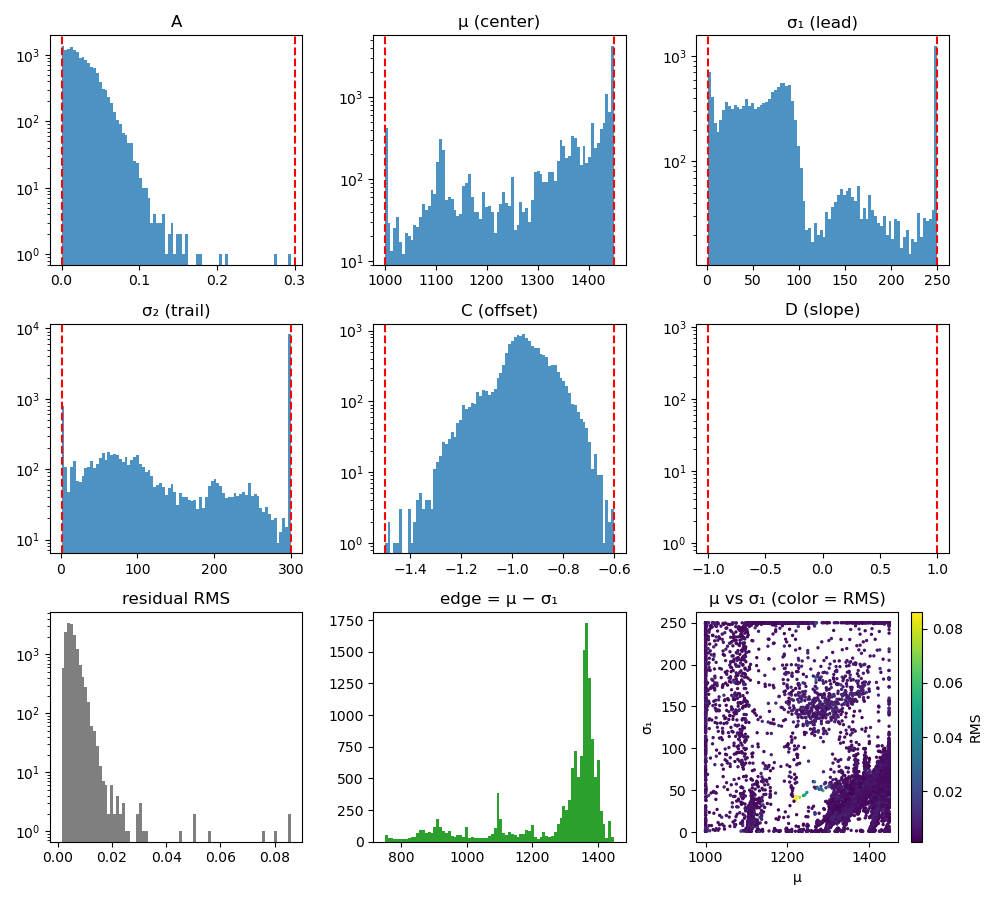

In [14]:
names = ['A', 'μ (center)', 'σ₁ (lead)', 'σ₂ (trail)', 'C (offset)', 'D (slope)']
P = params_fit                                   # (N_on, 6)
N = len(P)

# fit quality: per-shot residual RMS of the fitted model vs the data it was fit to
model = np.array([asymmetric_gaussian(x, *P[i]) for i in range(N)])
rms   = np.sqrt(np.nanmean((spectra - model)**2, axis=1))

# flag fits that just returned the moment seed (curve_fit failed / NaN seed)
seed = np.column_stack([params[:,0], params[:,1], params[:,2]/2,
                        params[:,2], params[:,3], params[:,4]])
fell_back = (np.all(np.isclose(P, np.clip(seed, lb, ub)), axis=1)
             | ~np.isfinite(P[:, :3]).all(axis=1))

tol = 1e-3 * (ub - lb)                            # "sitting on the bound" tolerance
print(f'{N} on-shots | seed-fallback (no real fit): {fell_back.sum()} '
      f'({100*fell_back.mean():.1f}%) | median resid RMS {np.nanmedian(rms):.4f}')
print('param         %@lb   %@ub    median')
for j, nm in enumerate(names):
    at_lb = 100*np.mean(np.isclose(P[:,j], lb[j], atol=tol[j]))
    at_ub = 100*np.mean(np.isclose(P[:,j], ub[j], atol=tol[j]))
    print(f'{nm:12s} {at_lb:6.1f} {at_ub:6.1f}   {np.nanmedian(P[:,j]):.3f}')

fig, ax = plt.subplots(3, 3, figsize=(10, 9)); ax = ax.ravel()
for j, nm in enumerate(names):
    ax[j].hist(P[:,j], bins=80, color='tab:blue', alpha=0.8); ax[j].set_yscale('log')
    ax[j].axvline(lb[j], c='r', ls='--'); ax[j].axvline(ub[j], c='r', ls='--')
    ax[j].set_title(nm)
ax[6].hist(rms, bins=80, color='tab:gray');            ax[6].set_yscale('log'); ax[6].set_title('residual RMS')
ax[7].hist(P[:,1]-P[:,2], bins=80, color='tab:green'); ax[7].set_title('edge = μ − σ₁')
sc = ax[8].scatter(P[:,1], P[:,2], c=rms, s=2, cmap='viridis')
ax[8].set_xlabel('μ'); ax[8].set_ylabel('σ₁'); ax[8].set_title('μ vs σ₁ (color = RMS)')
plt.colorbar(sc, ax=ax[8], label='RMS'); plt.tight_layout(); plt.show()

Plot a 2D maps of the input traces and compare them to the ones reconstructed fit (middle), and from Gaussian moment (right).

If the fit does not look like the data at all, go back to the previous cell and update the lower and upper bounds

Text(0, 0.5, 'frame (#)')

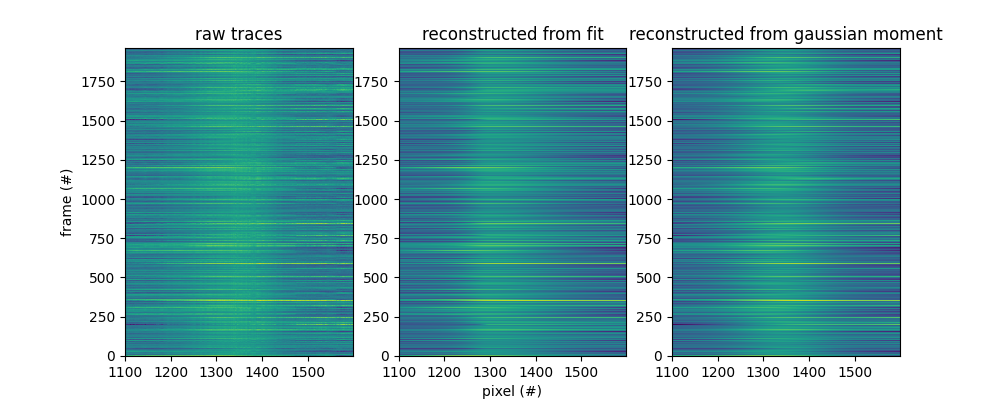

In [16]:
fit = np.array([
    asymmetric_gaussian(x, *params_fit[i,:])
    for i in range(spectra.shape[0])
])

fit_moment = np.array([
    asymmetric_gaussian(x, params[i,0], params[i,1], params[i,2], params[i,2], params[i,3], params[i,4])
    for i in range(spectra.shape[0])
])

fig,ax=plt.subplots(1,3,figsize=(10,4))
ax[0].pcolor(px, np.arange(spectra.shape[0]),spectra)
ax[0].set_title('raw traces')
ax[1].pcolor(px, np.arange(spectra.shape[0]),fit)
ax[1].set_title('reconstructed from fit')
ax[2].pcolor(px, np.arange(spectra.shape[0]),fit_moment)
ax[2].set_title('reconstructed from gaussian moment')

ax[1].set_xlabel('pixel (#)')
ax[0].set_ylabel('frame (#)')

Let's look at the distribution of edge positions - there's a lot of commented out lines, uncomment them if you want to compare the edge positions from different way of determining them, the label should tell you what they stand for

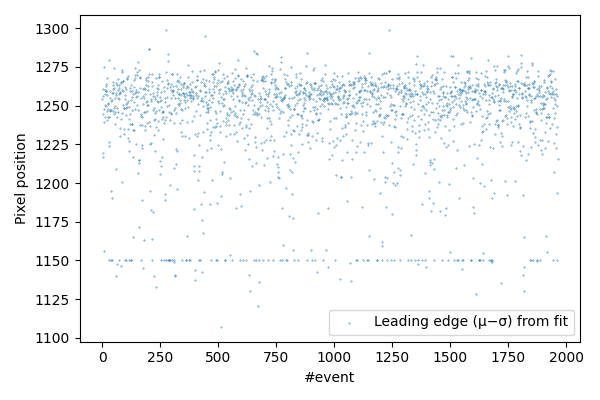

In [17]:


idx = np.arange(len(leading_edge))  # curve index, delay index, shot index, etc.

plt.figure(figsize=(6,4))
# plt.scatter(idx, leading_edge, s=.5, label="Leading edge (μ−σ) from gaussian mode")
plt.scatter(idx, leading_edge_fit, s=.1, label="Leading edge (μ−σ) from fit")
# plt.scatter(idx, leading_edge_max, s=.1, label="Leading edge (μ−σ) from max diff gaussian mode")
# plt.scatter(idx, leading_edge_fit_max, s=.1, label="Leading edge (μ−σ) from max diff fit")
# plt.plot(idx, leading_edge_fit-leading_edge, label="difference leading edge ")
# plt.scatter(idx, trailing_edge, s=5, label="Trailing edge (μ+σ)")
plt.xlabel("#event")
plt.ylabel("Pixel position")
plt.legend()
plt.tight_layout()
plt.show()

In [9]:
import numpy as np
from scipy.optimize import curve_fit
SQRT_E = np.sqrt(np.e)

def asym_gauss_lin(x, A, x0, s1, s2, k0, k1):
    """Asymmetric Gaussian peak split at the FITTED center x0, plus linear baseline."""
    g = np.where(x < x0,
                 A*np.exp(-(x-x0)**2/(2.0*s1**2)),
                 A*np.exp(-(x-x0)**2/(2.0*s2**2)))
    return g + k0 + k1*x

def fit_tt_edge(x, y, win=None, refit=True):
    """
    Fit one TT trace; return leading edge + quality.
    edge = x0 - |s1|  -> the max-slope point of the leading flank (sub-pixel,
    independent of how wide the fit came out). Works for a peak OR a dip.
    """
    x = np.asarray(x, float); y = np.asarray(y, float)
    if win is not None:
        m = (x >= win[0]) & (x <= win[1]); xf, yf = x[m], y[m]
    else:
        xf, yf = x, y

    # data-driven seed: linear baseline from the ends, then the dominant deviation
    k1_0 = (np.median(yf[-5:]) - np.median(yf[:5])) / (xf[-1] - xf[0] + 1e-9)
    k0_0 = np.median(yf[:5]) - k1_0*xf[0]
    dev  = yf - (k0_0 + k1_0*xf)
    if abs(np.nanmin(dev)) > abs(np.nanmax(dev)):      # dip
        A0, x0_0 = np.nanmin(dev), xf[np.nanargmin(dev)]
    else:                                              # peak
        A0, x0_0 = np.nanmax(dev), xf[np.nanargmax(dev)]
    p0 = [A0, x0_0, 15.0, 30.0, k0_0, k1_0]

    try:
        popt, _ = curve_fit(asym_gauss_lin, xf, yf, p0=p0, maxfev=20000)
        if refit:
            popt, _ = curve_fit(asym_gauss_lin, xf, yf, p0=popt, maxfev=20000)
        ok = True
    except Exception:
        popt, ok = np.array(p0, float), False

    A, x0, s1, s2, k0, k1 = popt
    s1 = abs(s1); s2 = abs(s2)
    edge      = x0 - s1                                 # leading inflection, sub-pixel
    max_slope = abs(A)/(s1*SQRT_E)                       # slope value at the edge
    rms       = np.sqrt(np.nanmean((yf - asym_gauss_lin(xf, *popt))**2))
    return dict(edge=edge, A=A, x0=x0, s1=s1, s2=s2,
                max_slope=max_slope, rms=rms, ok=ok)

def fit_tt_edges(px, spectra, win=None):
    """Batch over on-shot traces (spectra already = the laser-on rows)."""
    keys = ['edge','A','x0','s1','s2','max_slope','rms']
    out  = {k: np.full(spectra.shape[0], np.nan) for k in keys}
    out['ok'] = np.zeros(spectra.shape[0], bool)
    for i in range(spectra.shape[0]):
        r = fit_tt_edge(px, spectra[i], win=win)
        for k in keys: out[k][i] = r[k]
        out['ok'][i] = r['ok']
    return out

In [10]:

px = np.arange(ROI[0],ROI[1])
x = px
spectra = -traces[mask_on[:]]
res  = fit_tt_edges(px, spectra, win=(1100, 1400))   # tight window around the ~1267 edge
edge = res['edge']
# quality cut: keep confident edges, drop weak/poorly-fit shots
good = res['ok'] & (res['max_slope'] > np.nanpercentile(res['max_slope'], 5)) \
                 & (res['rms']       < np.nanpercentile(res['rms'], 95))
edge_clean = np.where(good, edge, np.nan)
print(f'kept {100*good.mean():.1f}% of shots; edge median {np.nanmedian(edge_clean):.1f} px')

/lscratch/yzy25/tmp/ipykernel_3659929/3502982313.py:37: OptimizeWarning: Covariance of the parameters could not be estimated
  popt, _ = curve_fit(asym_gauss_lin, xf, yf, p0=popt, maxfev=20000)
/lscratch/yzy25/tmp/ipykernel_3659929/3502982313.py:35: OptimizeWarning: Covariance of the parameters could not be estimated
  popt, _ = curve_fit(asym_gauss_lin, xf, yf, p0=p0, maxfev=20000)


kept 90.0% of shots; edge median 1189.4 px


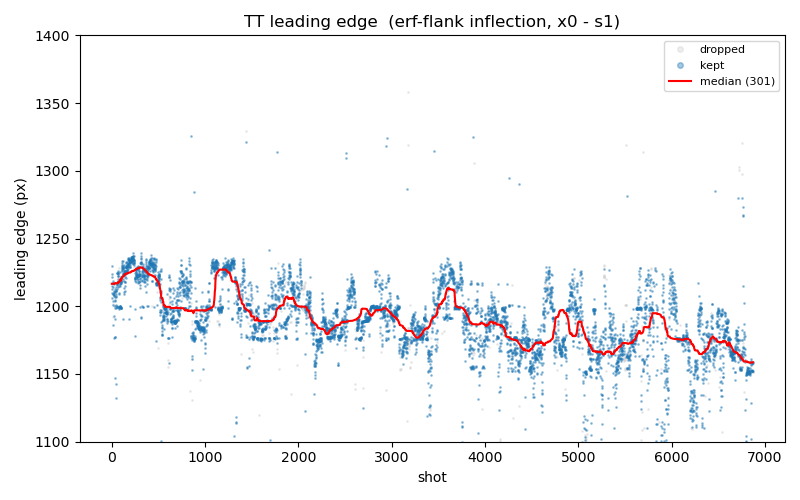

In [11]:
import matplotlib.pyplot as plt
from scipy.ndimage import median_filter

shot = np.arange(spectra.shape[0])

fig, ax = plt.subplots(figsize=(8, 5))
ax.plot(shot[~good], edge[~good], '.', ms=2, color='lightgray', alpha=.4, label='dropped')
ax.plot(shot[good],  edge[good],  '.', ms=2, color='tab:blue',  alpha=.4, label='kept')

# robust drift trend through the kept edges
if good.sum() > 51:
    sg, eg = shot[good], edge[good]
    k = min(301, (eg.size // 2) * 2 + 1)          # odd, <= n
    ax.plot(sg, median_filter(eg, size=k), 'r-', lw=1.5, label=f'median ({k})')

ax.set_xlabel('shot'); ax.set_ylabel('leading edge (px)')
ax.set_title('TT leading edge  (erf-flank inflection, x0 - s1)')
ax.legend(markerscale=4, fontsize=8)
ax.set_ylim(1100,1400)
plt.tight_layout()

In [12]:
# fill the quality-cut dropped shots with the median of the kept ones, then save
edge_save = edge.copy()
med = np.nanmedian(edge_save[good])      # median of confidently-fit shots
edge_save[~good] = med                    # previously-dropped shots -> median
edge_save[np.isnan(edge_save)] = med      # safety: any leftover NaN -> median

np.savetxt(f"proc/leading_edge_{run}.txt", edge_save)
print(f"saved {edge_save.size} edges -> proc/leading_edge_{run}.txt | "
      f"median = {med:.2f} px | filled {(~good).sum()}/{edge_save.size} shots "
      f"({100*(~good).mean():.1f}%)")

saved 6873 edges -> proc/leading_edge_62.txt | median = 1189.39 px | filled 686/6873 shots (10.0%)


In [16]:
# DROP bad shots: NaN them. Their corrected delay -> NaN -> excluded by np.digitize.
# Length unchanged, so it stays aligned with scanvar[onmask].
edge_save = np.where(good, edge, np.nan)
np.savetxt(f"proc/leading_edge_{run}.txt", edge_save)
print(f"saved {edge_save.size} edges -> proc/leading_edge_{run}.txt | "
      f"dropped (NaN) {(~good).sum()}/{edge_save.size} ({100*(~good).mean():.1f}%)")

saved 14736 edges -> proc/leading_edge_113.txt | dropped (NaN) 1551/14736 (10.5%)


NameError: name 'mu_fit' is not defined

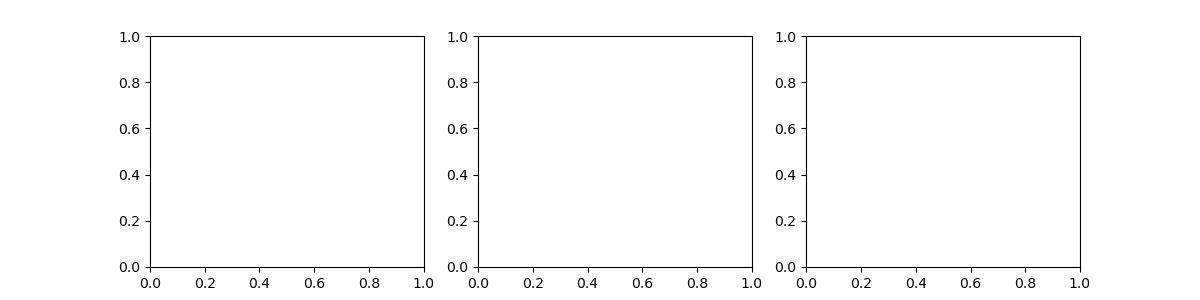

In [15]:
fig, ax = plt.subplots(1, 3, figsize=(12,3), sharex=True)
ax[0].scatter(np.arange(len(mu_fit)),    mu_fit,           s=.1); ax[0].set_title('mu')
ax[1].scatter(np.arange(len(sigma_fit1)), sigma_fit1,      s=.1); ax[1].set_title('sigma1')
ax[2].scatter(np.arange(len(mu_fit)),    mu_fit-sigma_fit1, s=.1); ax[2].set_title('mu - sigma')

## Define ROI and save

From the scatter plot above determine the ROI and determine the low and high of the ROI, everything outside of that range will be set to the mean of the points inside the ROI

POSSIBLE IMPROVEMENT: instead of just using the mean, we coudl implement a nearest neighbour interpolation here


The results here will be saved to a txt file that will then be loaded when binning the data in 'process.py' to correct the nominal timing

In some cases with a very damaged target, the Gaussian moment seems to give a better estimate of the edge position than the fit, int that case set 'usefit' to False

In [ ]:

# np.savetxt(f"proc/leading_edge1{run}.txt", leading_edge)
low = 1180
high =1230
usefit = True # if true use fit, if false use Gaussian moment

if usefit:
    mean = np.nanmean(leading_edge_fit[np.logical_and(leading_edge_fit<high,leading_edge_fit>low)])
    leading_edge_fit[leading_edge_fit>high]=mean
    leading_edge_fit[leading_edge_fit<low]=mean
    # np.savetxt(f"proc/leading_edge_{run}.txt", leading_edge_fit)
else:
    mean = np.nanmean(leading_edge[np.logical_and(leading_edge<high,leading_edge>low)])
    leading_edge[leading_edge>high]=mean
    leading_edge[leading_edge<low]=mean
    # np.savetxt(f"proc/leading_edge_{run}.txt", leading_edge)



494/3699 replaced (13.4%), fill mean = 1120.53 px, NaNs left = 0


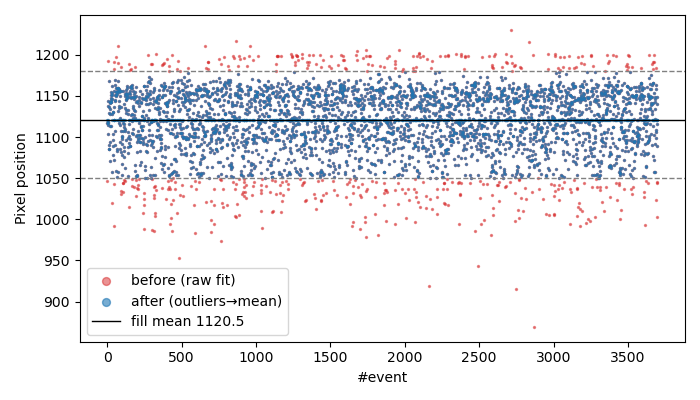

In [13]:
low, high = 1050, 1180

raw = leading_edge_fit.copy()                      # before
inwin = (raw > low) & (raw < high)
mean = np.nanmean(raw[inwin])

clipped = raw.copy()                               # after
clipped[raw > high] = mean
clipped[raw < low]  = mean

n_clip = np.sum(~inwin & ~np.isnan(raw))
print(f'{n_clip}/{len(raw)} replaced ({100*n_clip/len(raw):.1f}%), '
      f'fill mean = {mean:.2f} px, NaNs left = {np.isnan(clipped).sum()}')

idx = np.arange(len(raw))
plt.figure(figsize=(7,4))
plt.scatter(idx, raw,     s=2, c='tab:red',  alpha=0.5, label='before (raw fit)')
plt.scatter(idx, clipped, s=2, c='tab:blue', alpha=0.6, label='after (outliers→mean)')
plt.axhline(low,  ls='--', c='gray', lw=1)
plt.axhline(high, ls='--', c='gray', lw=1)
plt.axhline(mean, ls='-',  c='k',    lw=1, label=f'fill mean {mean:.1f}')
plt.xlabel('#event'); plt.ylabel('Pixel position')
plt.legend(markerscale=4); plt.tight_layout(); plt.show()

In [14]:
from scipy.spatial import cKDTree

def knn_aggregate(coords, values, mask_good, k=50, queries=None, agg=np.nanmean):
    """
    k-nearest-neighbour aggregation along an arbitrary coordinate.

    For each query sample, find the k nearest *good* samples (by distance in
    `coords`) and reduce their values with `agg`. General purpose: fill
    outliers/NaNs from local context, smooth a trace, interpolate onto good points.

    Parameters
    ----------
    coords : (N,) or (N, D) array
        Position of each sample for the distance metric. 1-D -> nearest in
        index/time/energy; N-D -> nearest in that space. np.arange(N) gives
        plain acquisition-order neighbours.
    values : (N,) array            values to aggregate
    mask_good : (N,) bool          samples allowed to act as neighbours (in-ROI, finite)
    k : int                        number of nearest good neighbours
    queries : (M,) int, optional   sample indices to estimate (default: all N)
    agg : callable                 reduction over neighbours, axis=1 (nanmean, nanmedian, ...)

    Returns
    -------
    est : (M,) array               aggregated neighbour value per query
    """
    coords = np.asarray(coords, float)
    if coords.ndim == 1:
        coords = coords[:, None]
    values = np.asarray(values, float)
    good = np.flatnonzero(mask_good)
    if good.size == 0:
        raise ValueError("no good samples to draw neighbours from")
    k = min(k, good.size)
    queries = np.arange(coords.shape[0]) if queries is None else np.asarray(queries)
    _, nn = cKDTree(coords[good]).query(coords[queries], k=k)
    if k == 1:
        nn = nn[:, None]
    return agg(values[good][nn], axis=1)

In [15]:
low, high = 1050, 1180
raw  = leading_edge_fit.copy()
good = (raw > low) & (raw < high) & np.isfinite(raw)     # in-ROI neighbours only
bad  = np.flatnonzero(~good)                              # outliers + NaNs

knn_filled = raw.copy()
knn_filled[bad] = knn_aggregate(np.arange(len(raw)), raw, good,
                                k=100, queries=bad, agg=np.nanmedian)

print(f'{bad.size}/{len(raw)} replaced ({100*bad.size/len(raw):.1f}%) via 50-NN local median')
# np.savetxt(f"proc/leading_edge_{run}.txt", knn_filled)

494/3699 replaced (13.4%) via 50-NN local median


In [16]:
low, high = 1170, 1225
mode   = 'drop'      # 'fill' = global mean | 'knn' = local median | 'drop' = ignore outliers
usefit = True       # True: use fit edge; False: use Gaussian-moment edge
k      = 100        # neighbours, knn mode only

raw  = (leading_edge_fit if usefit else leading_edge).copy()
good = (raw > low) & (raw < high) & np.isfinite(raw)
bad  = np.flatnonzero(~good)

edges = raw.copy()
if   mode == 'fill': edges[bad] = np.nanmean(raw[good])
elif mode == 'knn':  edges[bad] = knn_aggregate(np.arange(len(raw)), raw, good,
                                                 k=k, queries=bad, agg=np.nanmedian)
elif mode == 'drop': edges[bad] = np.nan
else: raise ValueError(f"unknown mode {mode!r}")

np.savetxt(f"proc/leading_edge_{run}.txt", edges)
note = {'fill': 'global mean', 'knn': f'{k}-NN local median', 'drop': 'NaN (dropped downstream)'}[mode]
print(f"[{mode}] {bad.size}/{len(raw)} outliers ({100*bad.size/len(raw):.1f}%) "
      f"outside [{low}, {high}] → {note}")

[drop] 619/3716 outliers (16.7%) outside [1170, 1225] → NaN (dropped downstream)


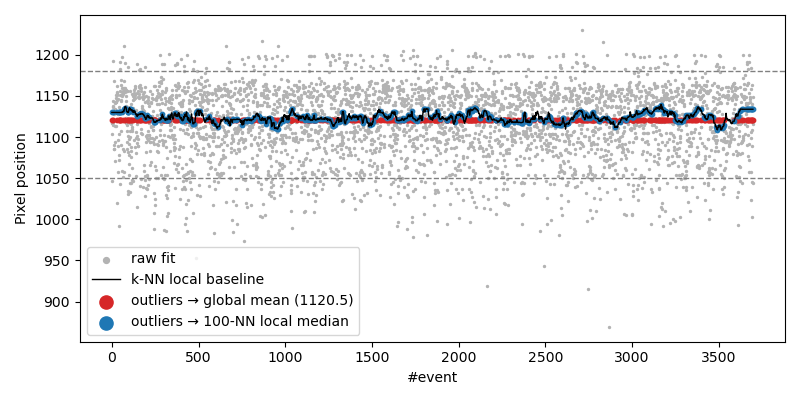

In [17]:
idx = np.arange(len(raw))

mean = np.nanmean(raw[good])                              # current behaviour
global_filled = raw.copy(); global_filled[~good] = mean

baseline = knn_aggregate(idx, raw, good, k=100, agg=np.nanmedian)  # local trend, all points

plt.figure(figsize=(8,4))
plt.scatter(idx, raw, s=2, c='0.7', label='raw fit')
plt.plot(idx, baseline, c='k', lw=1, label='k-NN local baseline')
plt.scatter(idx[~good], global_filled[~good], s=10, c='tab:red',
            label=f'outliers → global mean ({mean:.1f})')
plt.scatter(idx[~good], knn_filled[~good],   s=10, c='tab:blue',
            label='outliers → 100-NN local median')
plt.axhline(low, ls='--', c='gray', lw=1); plt.axhline(high, ls='--', c='gray', lw=1)
plt.xlabel('#event'); plt.ylabel('Pixel position')
plt.legend(markerscale=3); plt.tight_layout(); plt.show()

## Check if the edge position correlates with the nominal delay

Fortunately it doesn't seem to be the case, some weirdness at t=0

Text(0, 0.5, 'edge position')

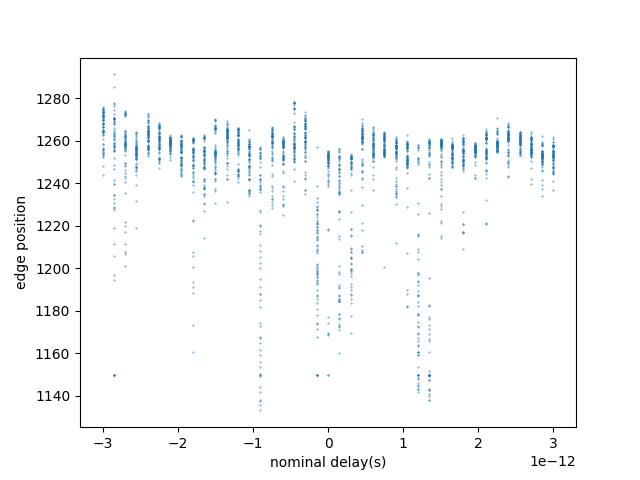

In [16]:
fig,ax=plt.subplots(1,1)
ax.scatter(data.integrating.axis_svls.delay[:][mask_on[:]],leading_edge_fit,s=0.1)
ax.set_xlabel('nominal delay(s)')
ax.set_ylabel('edge position')

Plot some of the traces together with fit (dashed line) and Gaussian moment (solid line)

Scatter x and dot mark the position of leading edge determined with Gaussian moment and fit, respectively

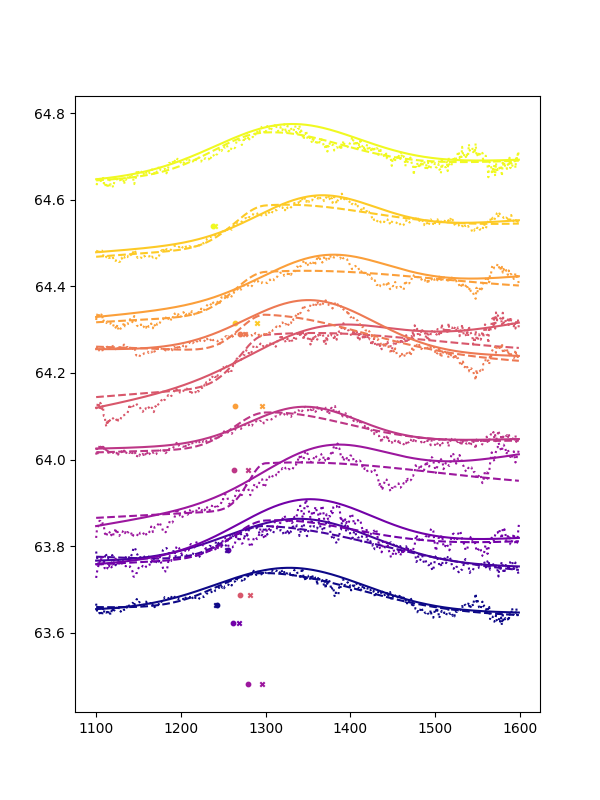

In [18]:
fig,ax =plt.subplots(1,1,figsize=(6,8))



cmap = mpl.colormaps['plasma']
colors = cmap(np.linspace(0, 1, len(np.arange(580,590,1))))


f=2
c=0
for i in np.arange(580,590,1):
    ax.plot(px,asymmetric_gaussian(px,params[i,0], params[i,1], params[i,2], params[i,2], params[i,3], params[i,4])+params[0,0]*i*f,color=colors[c])
    ax.plot(px,asymmetric_gaussian(px,*params_fit[i,:])+params[0,0]*i*f,'--',color=colors[c])
    ax.plot(px,spectra[i]+params[0,0]*i*f,':',color=colors[c])
    ax.scatter(leading_edge[i],params[0,0]*i*f+params[i,-2],s=10,marker='x',color=colors[c])
    ax.scatter(leading_edge_fit[i],params[0,0]*i*f+params[i,-2],s=10,marker='o',color=colors[c])
    c=c+1

In [25]:
import h5py
key = 'intg/axis_svls/c_piranha_sum_full_area'      # 'piranha' is the chemrixs alias for this
with h5py.File(fname, 'r') as f:
    raw = f[key].shape[0]
filt = proc.data.integrating.axis_svls.piranha.shape[0]
print(f'raw {raw}, after countmask {filt}, dropped {raw-filt} ({100*(raw-filt)/raw:.1f}%)')

raw 28909, after countmask 15568, dropped 13341 (46.1%)


In [14]:
def load_epics(fh):
    '''Loads the epics archiver variables from h5 file.
    Note the shape varies
    '''
    epics_keys = [('epics_archiver', 'CRIX_VLS_CAM_MMS_PITCH.RBV', 'VLS_camera_pitch'),
                  ('epics_archiver', 'CRIX_VLS_MMS_GP.RBV', 'VLS_grating_pitch_mm'),
                  ('epics_archiver', 'CRIX_VLS_MMS_MP.RBV', 'VLS_mirror_pitch_mm'),
                  ('epics_archiver', 'LM2K2_COM_MP2_DLY1.RBV', 'ATM_stage_mm'),
                  ('epics_archiver', 'SP1K1_MONO_MMS_G_PI.RBV', 'MONO_grating_pitch'),
                  ('epics_archiver', 'SP1K1_MONO_MMS_M_PI.RBV', 'MONO_premirror_pitch'),
                  ('epics_archiver','SP1K1_MONO_CALC_ENERGY','MONO_Calc_energy')
           ]
    dat = {}
    for i, k in enumerate(epics_keys):
        try:
            dat[k[2]] = fh[k[0]][k[1]][...][:,1]
        except: print(f'Missing epics key {k[1]}')
    return dat
def load_int_data(fh,prefix = '', load_ttfex = True,evc_laser_on = 272, evc_laser_off = 273,evc_laser_any=274, roll = True, int_detector_key=None,idx_scan_var = 0):
    data = {}
    ## This is for the small data structure for run 24 (at least up to date for May Cobalt experiment)
    if 'intg' in fh.keys():
        if int_detector_key is None:
            int_detector_key = 'intg/axis_svls'
            # int_detector_key = 'intg/andor_vls'
    
        keys_andor = [('intg/andor_dir',f'{prefix}full_area','dir'),
                ('intg/andor_vls',f'{prefix}full_area','vls'),
                ('intg/andor_vls',f'{prefix}hitfinder','vls_hitfound'),
                ('intg/andor_norm',f'{prefix}full_area','norm')]
                #('intg/axis_svls',f'{prefix}curve_corr_pj_ax_1_data','svls')
                # ,('intg/axis_svls',f'{prefix}curve_corr_corrected_projection','svls')
               #]
        
        if 'intg/axis_svls/curve_corr_pj_ax_1_data' in fh.keys():
            keys_andor.append(('intg/axis_svls',f'{prefix}curve_corr_pj_ax_1_data','svls'))

        if 'intg/axis_svls/droplet_dense_curve_corr_pj_ax_1_data' in fh.keys():
            keys_andor.append(('intg/axis_svls',f'{prefix}droplet_dense_curve_corr_pj_ax_1_data','svls'))
            
        if 'intg/axis_svls/curve_corr_corrected_projection' in fh.keys():
            keys_andor.append(('intg/axis_svls',f'{prefix}curve_corr_corrected_projection','svls'))
            
        keys_int = [(int_detector_key,f'{prefix}fzp_piranha_sum_full_area','fzp_piranha'),
                    (int_detector_key ,f'{prefix}det_rix_fim1_sum_full_area','fim1_wf'),
                    (int_detector_key ,f'{prefix}det_rix_fim0_sum_full_area','fim0_wf'),
                    (int_detector_key ,f'{prefix}det_crix_w8_sum_full_area','apd_wf'),
                    (int_detector_key ,f'{prefix}hsd_sum_full_hsd_1__ROI_wf','hsd1_wf'),
                    (int_detector_key ,f'{prefix}det_rix_fim1_sum_wfintegrate','fim1_sum'),
                    (int_detector_key ,f'{prefix}det_rix_fim0_sum_wfintegrate','fim0_sum'),
                    (int_detector_key ,f'{prefix}det_crix_w8_sum_wfintegrate','apd_sum'),
                    (int_detector_key ,f'{prefix}mono_encoder_sum_interpolated_value','mono_encoder'),
                    (int_detector_key ,f'{prefix}mono_encoder_sum_raw_value','mono_encoder_lowrate'),
                    (int_detector_key ,f'{prefix}mono_hrencoder_sum_value','mono_hrencoder'),
                    (int_detector_key ,f'{prefix}c_piranha_sum_full_area','pir'),
                    (int_detector_key ,f'{prefix}timing_sum_eventcodes','evc'),
                    (int_detector_key ,f'{prefix}timing_sum_destination','dest')
                       ]
        if 'scan' in fh.keys():
            ### position 0 is now "step_value" for the latest smd iteration
            scan_var_name = list(fh['scan'].keys())[idx_scan_var]
            keys_int.append((int_detector_key ,f'{prefix}scan_sum_%s'%scan_var_name,'scan_var'))
            keys_int.append((int_detector_key ,f'{prefix}scan_sum_step_value','step'))
        
        # These should not be normalized to count
        keys_ts = [(int_detector_key ,f'{prefix}timestamp_min','timestamp_min'),
                (int_detector_key ,f'{prefix}timestamp_max','timestamp_max'),
                (int_detector_key ,f'{prefix}timing_sum_timestamp','timestamp_norm')
                   ]
        if load_ttfex:
            keys_int = keys_int + [(int_detector_key ,f'{prefix}tt_sum_fltpos','pos'),
                (int_detector_key ,f'{prefix}tt_sum_fltposfwhm','fwhm'),
                (int_detector_key ,f'{prefix}tt_sum_ampl','amp')
               ]
    else:
        if int_detector_key is None:
            int_detector_key = 'andor_vls'
        keys_andor = [('andor_dir',f'{prefix}grp_intg_full_area','dir'),
                ('andor_vls',f'{prefix}grp_intg_full_area','vls'),
                ('andor_vls',f'{prefix}hitfinder','vls_hitfound'),
                ('andor_norm',f'{prefix}grp_intg_full_area','norm'),
               ]
    
        keys_int = [(int_detector_key ,f'{prefix}grp_intg_norm_det_rix_fim1_sum_full_area','fim1_wf'),
                (int_detector_key ,f'{prefix}grp_intg_norm_det_rix_fim0_sum_full_area','fim0_wf'),
                (int_detector_key ,f'{prefix}grp_intg_norm_det_crix_w8_sum_full_area','apd_wf'),
                (int_detector_key ,f'{prefix}grp_intg_norm_det_rix_fim1_sum_wfintegrate','fim1_sum'),
                (int_detector_key ,f'{prefix}grp_intg_norm_det_rix_fim0_sum_wfintegrate','fim0_sum'),
                (int_detector_key ,f'{prefix}grp_intg_norm_det_crix_w8_sum_wfintegrate','apd_sum'),
                (int_detector_key ,f'{prefix}grp_intg_norm_mono_hrencoder_sum_value','mono_hrencoder'),
                (int_detector_key ,f'{prefix}grp_intg_norm_c_piranha_sum_full_area','pir'),
                (int_detector_key ,f'{prefix}grp_intg_norm_timing_sum_eventcodes','evc'),
                (int_detector_key ,f'{prefix}grp_intg_norm_timing_sum_destination','dest')
                   ]
        
        if 'scan' in fh.keys():
            scan_var_name = list(fh['scan'].keys())[idx_scan_var]
            keys_int.append((int_detector_key ,f'{prefix}grp_intg_norm_scan_sum_%s'%scan_var_name,'scan_var'))
            
        # These should not be normalized to count
        keys_ts = [(int_detector_key ,f'{prefix}grp_intg_norm_timestamp_min','timestamp_min'),
                (int_detector_key ,f'{prefix}grp_intg_norm_timestamp_max','timestamp_max'),
                (int_detector_key ,f'{prefix}grp_intg_norm_timing_sum_timestamp','timestamp_norm')
                   ]

        if load_ttfex:
            keys_int = keys_int + [(int_detector_key ,f'{prefix}tt_sum_fltpos','pos'),
                (int_detector_key ,f'{prefix}tt_sum_fltposfwhm','fwhm'),
                (int_detector_key ,f'{prefix}tt_sum_ampl','amp')
               ]

    data = {}
    # Load timestamps 
    if 'intg' in fh.keys():
        data['timestamp'] = np.array(fh['intg/timestamp'])
        data['count'] = np.array(fh[int_detector_key][f'{prefix}count'])

    else:
        data['timestamp'] = np.array(fh[int_detector_key+'/grp_intg_norm_timing_sum_timestamp'])
        data['count'] = np.array(fh[int_detector_key][f'{prefix}grp_intg_norm_count'])

    # summed timestamps
    for key in keys_ts:
        #data[key[2]] = np.array(fh[key[0]][key[1]])
        try:
            data[key[2]] = np.array(fh[key[0]][key[1]]) 
        except:
            print('missing key {0}'.format(key))
    
    # Load andor images
    for key in keys_andor:
        try:
            data[key[2]] = np.array(fh[key[0]][key[1]]) 
        except:
                print('missing key {0}'.format(key))

    # Normalize these parameters to the number of single shots per image
    for key in keys_int:
        #data[key[2]] = np.array(fh[key[0]][key[1]], chunks=chunks) 
        try:
            data[key[2]] = np.array(fh[key[0]][key[1]])
            expected_count = st.mode(data['count'],keepdims=False)[0]
            count_reset = data['count'].copy()
            count_reset[(count_reset==(expected_count+1))|(count_reset==expected_count)]=expected_count
            if (key[2] == 'scan_var') | (key[2]=='step'):
                if len(data[key[2]].shape)==1:
                    data[key[2]] = data[key[2]]/data['count']
                elif len(data[key[2]].shape)==2:
                    data[key[2]] = data[key[2]]/data['count'][:,np.newaxis]
                elif len(data[key[2]].shape)==3:
                    data[key[2]] = data[key[2]]/data['count'][:,np.newaxis,np.newaxis]
            else:
                if len(data[key[2]].shape)==1:
                    data[key[2]] = data[key[2]]/count_reset
                elif len(data[key[2]].shape)==2:
                    data[key[2]] = data[key[2]]/count_reset[:,np.newaxis]
                elif len(data[key[2]].shape)==3:
                    data[key[2]] = data[key[2]]/count_reset[:,np.newaxis,np.newaxis]
        except:
            print('missing key {0}'.format(key))
    data['count']=count_reset
    # Generate a xray on and laser on 
    data['laser_on'] =  data['evc'][:,evc_laser_on]>0.5
    data['laser_off'] = data['evc'][:,evc_laser_off]>0.5
    data['laser_any'] = data['evc'][:,evc_laser_any]>0.5
    data['xray_on'] = data['dest']==4
    data['dest'] = data['dest']

    idx = np.argsort(data['timestamp'])
    # Sort data by timestamp
    for k in data.keys():
        data[k] = data[k][idx]
    # Roll the andor images to account for andor trigger delay
    if roll:
        for key in keys_andor:
            try:
                data[key[2]] = np.roll(data[key[2]],1,axis = 0)
            except:
                print('missing key {0}'.format(key))
        # cropp all data 
        for key, value in data.items():
            #print(value.shape)
            data[key] = value[1:]
            #print(data[key].shape)
            

    # Load epics_archiver variables
    epics_data = load_epics(fh)
    data['epics'] = epics_data
    if 'scan' in fh.keys():
        data['scan_var_name']=np.array([scan_var_name])
        if np.logical_or(scan_var_name =='lxt',scan_var_name == 'lxt_ttc'):
            data['scan_var'] = np.squeeze(data['scan_var']*1e12)
    data['run'] = np.array([int(fh.filename[-7:-3])])
    return data

In [15]:
import numpy as np, h5py
ROI = [1100, 1400]; N = 2000; neigs = 3        # set to Plot_Time's exact values

# ---------- Path A: Plot_Time's own loader (ground truth) ----------
with h5py.File(fname, 'r') as fh:
    dat = load_int_data(fh, load_ttfex=True, int_detector_key='intg/axis_svls')
pir_A, lon_A = dat['pir'], dat['laser_on']
loff_A = ~lon_A

# ---------- Path B: raw read, replicating load_int_data's transforms ----------
with h5py.File(fname, 'r') as fh:
    pir_raw = np.array(fh['intg/axis_svls/c_piranha_sum_full_area']).astype(float)
    evc_raw = np.array(fh['intg/axis_svls/timing_sum_eventcodes'])
    cnt_raw = np.array(fh['intg/axis_svls/count']).astype(float)
    ts_raw  = np.array(fh['intg/timestamp'])

idx   = np.argsort(ts_raw)
pir_B = pir_raw[idx][1:]                        # same sort + [1:] crop
evc_B = evc_raw[idx][1:]
cnt_B = cnt_raw[idx][1:]
lon_B = (evc_B[:, 272] / cnt_B) > 0.5
loff_B = ~lon_B

# ---------- stage diffs: find where A and B split ----------
print('shape A/B      :', pir_A.shape, pir_B.shape)
same = pir_A.shape == pir_B.shape
print('pir allclose   :', same and np.allclose(pir_A, pir_B, equal_nan=True))
if same and not np.allclose(pir_A, pir_B, equal_nan=True):
    r = pir_A / np.where(pir_B == 0, np.nan, pir_B)
    print('  ratio A/B  : median', np.nanmedian(r),
          '| per-row spread', np.nanstd(np.nanmedian(r, axis=1)))   # ~0 spread => global; >0 => per-row
print('lon  identical :', same and np.array_equal(lon_A, lon_B))
print('loff counts    :', int(loff_A.sum()), int(loff_B.sum()))

missing key ('intg/andor_dir', 'full_area', 'dir')
missing key ('intg/andor_vls', 'full_area', 'vls')
missing key ('intg/andor_vls', 'hitfinder', 'vls_hitfound')
missing key ('intg/andor_norm', 'full_area', 'norm')
missing key ('intg/axis_svls', 'hsd_sum_full_hsd_1__ROI_wf', 'hsd1_wf')
missing key ('intg/axis_svls', 'mono_encoder_sum_interpolated_value', 'mono_encoder')
missing key ('intg/axis_svls', 'mono_encoder_sum_raw_value', 'mono_encoder_lowrate')
missing key ('intg/andor_dir', 'full_area', 'dir')
missing key ('intg/andor_vls', 'full_area', 'vls')
missing key ('intg/andor_vls', 'hitfinder', 'vls_hitfound')
missing key ('intg/andor_norm', 'full_area', 'norm')
shape A/B      : (28908, 2048) (28908, 2048)
pir allclose   : False
  ratio A/B  : median 0.0029850746268656717 | per-row spread 8.673617379884035e-19
lon  identical : True
loff counts    : 14454 14454


In [17]:
print('on match:', np.array_equal(mask_on[1:], lon_B))     # expect False
d = np.flatnonzero(mask_on[1:] ^ lon_B)
print('# differing frames:', d.size, '| first few:', d[:15])

i = d[0]                                    # inspect one disagreeing frame
print('TT      frac:', ev[1:][i,272]/cnt[1:][i], '-> on=', bool(mask_on[1:][i]))
print('harness frac:', evc_B[i,272]/cnt_B[i],           '-> on=', bool(lon_B[i]))

on match: False
# differing frames: 28908 | first few: [ 0  1  2  3  4  5  6  7  8  9 10 11 12 13 14]
TT      frac: 0.0029850746268656717 -> on= True
harness frac: 0.0029850746268656717 -> on= False


In [18]:
print(data.yaml['evc'])              # expect {True: 273, False: 272}  <- wrong way round
print('evc[True] =', data.yaml['evc'][True])

{True: 273, False: 272, 'any': 274}
evc[True] = 273


In [6]:
import h5py, numpy as np, scipy.stats as st
import matplotlib.pyplot as plt

run = 114
fname = f'{base_folder}/{exp}/hdf5/smalldata/{exp}_Run{run:04d}.h5'
g = 'intg/axis_svls'
with h5py.File(fname,'r') as f:
    count = f[f'{g}/count'][()].squeeze()
    evc   = f[f'{g}/timing_sum_eventcodes'][()]
    svls  = f[f'{g}/droplet_dense_curve_corr_pj_ax_1_data'][()].astype(float)
    pir   = f[f'{g}/c_piranha_sum_full_area'][()].astype(float)
    hren  = f[f'{g}/mono_hrencoder_sum_value'][()].squeeze()

N = len(count); mode = int(st.mode(count, keepdims=False)[0])
safe = np.where(count>0, count, 1)
maj272 = (evc[:,272]/safe) > 0.5
pfy = np.nansum(svls, 1)

# locate the piranha edge with a parity bootstrap (laser ~ alternates) -- no eventcodes used
roi = slice(1100, 1400)
par = (np.arange(N) % 2).astype(bool)
edge = np.nanmean(pir[par][:, roi], 0) - np.nanmean(pir[~par][:, roi], 0)
x0 = roi.start + int(np.nanargmax(np.abs(edge)));  w = 60
pir_tag = np.nanmean(pir[:, x0-w:x0], 1) - np.nanmean(pir[:, x0:x0+w], 1)   # per-frame, label-free
pir_on  = pir_tag > np.nanmedian(pir_tag)
print('edge bin =', x0, ' | piranha-tag vs evc272 agreement:',
      round(max(np.mean(pir_on==maj272), np.mean(pir_on==~maj272)), 3))

edge bin = 1252  | piranha-tag vs evc272 agreement: 0.516


In [7]:
print('svls vs PIRANHA-defined laser-on   offset : svls PFY contrast')
for o in (-1, 0, 1):
    m = np.roll(pir_on, o)
    print(f'   {o:+d} : {np.nanmean(pfy[m]) - np.nanmean(pfy[~m]):+.3e}')

svls vs PIRANHA-defined laser-on   offset : svls PFY contrast
   -1 : +9.274e+01
   +0 : +8.860e+01
   +1 : +8.962e+01


Text(0.5, 1.0, 'SVLS on-off vs encoder (axis reversed vs eV) - which dips at L3?')

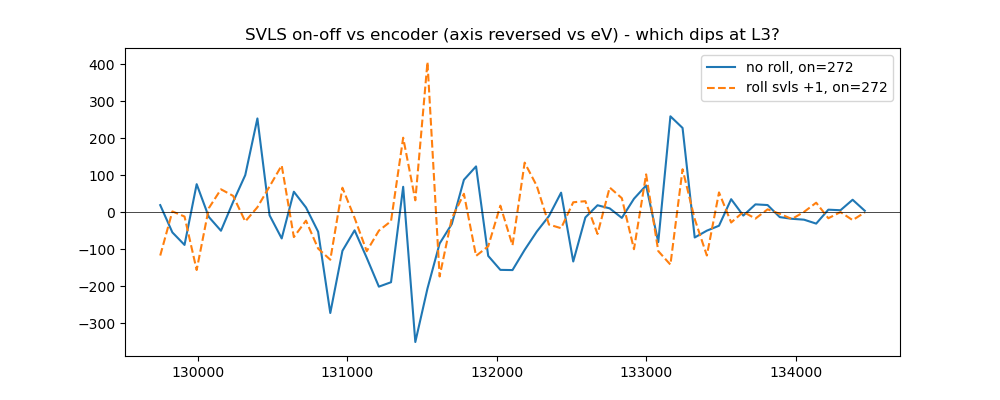

In [8]:
mono = hren / mode
edges = np.linspace(np.percentile(mono,1), np.percentile(mono,99), 60)
ctr = 0.5*(edges[:-1]+edges[1:])
def diff(pfyv):
    on, off = maj272, ~maj272
    son,_=np.histogram(mono[on], edges, weights=pfyv[on]); non,_=np.histogram(mono[on], edges)
    sof,_=np.histogram(mono[off],edges, weights=pfyv[off]); nof,_=np.histogram(mono[off],edges)
    return son/np.maximum(non,1) - sof/np.maximum(nof,1)

plt.figure(figsize=(10,4))
plt.plot(ctr, diff(pfy),            label='no roll, on=272')          # my position
plt.plot(ctr, diff(np.roll(pfy,1)), '--', label='roll svls +1, on=272')  # your hypothesis
plt.axhline(0, color='k', lw=0.5); plt.legend()
plt.title('SVLS on-off vs encoder (axis reversed vs eV) - which dips at L3?')

laser vs frame-parity correlation: 0.502


Text(0.5, 1.0, 'piranha on(272)-off(273) edge, peak at 1267 -- does this match your expected TT edge?')

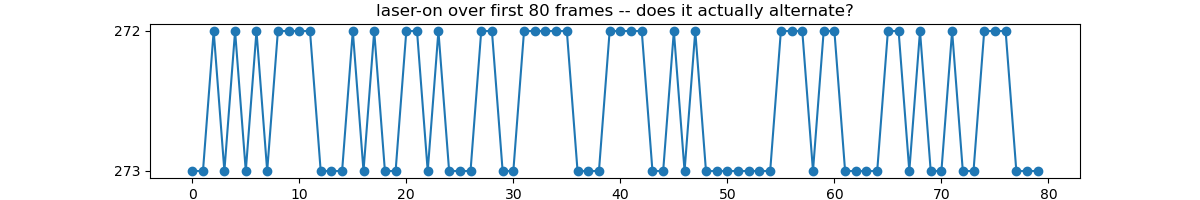

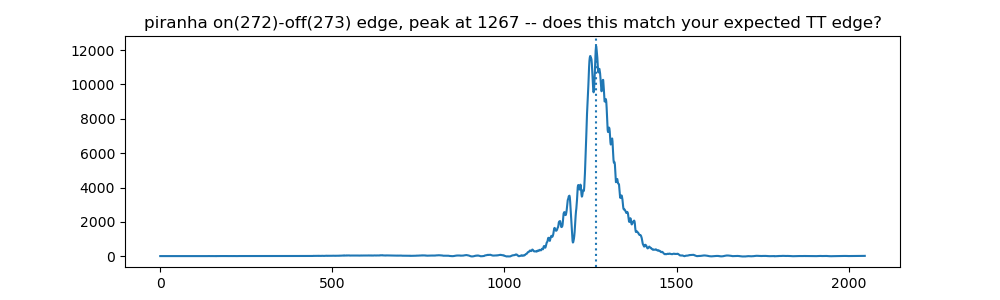

In [9]:
# A: actual laser cadence + the REAL piranha edge (built from eventcodes, not parity)
print('laser vs frame-parity correlation:',
      round(np.mean(maj272 == (np.arange(N)%2==1)), 3))   # ~0.5 => not every-other-frame in index order
plt.figure(figsize=(12,2)); plt.plot(maj272[:80],'o-'); plt.yticks([0,1],['273','272'])
plt.title('laser-on over first 80 frames -- does it actually alternate?')

edge = np.nanmean(pir[maj272],0) - np.nanmean(pir[~maj272],0)
x0 = int(np.nanargmax(np.abs(edge)))
plt.figure(figsize=(10,3)); plt.plot(edge); plt.axvline(x0, ls=':')
plt.title(f'piranha on(272)-off(273) edge, peak at {x0} -- does this match your expected TT edge?')

In [10]:
# B: svls vs piranha relative alignment, using the real edge location from A
pir_scalar = np.nanmean(pir[:, x0-60:x0], 1) - np.nanmean(pir[:, x0:x0+60], 1)
print('offset :   svls contrast |  piranha contrast   (both vs evc-272)')
for o in (-1, 0, 1):
    m = np.roll(maj272, o)
    cs = np.nanmean(pfy[m]) - np.nanmean(pfy[~m])
    cp = np.nanmean(pir_scalar[m]) - np.nanmean(pir_scalar[~m])
    print(f'  {o:+d}   : {cs:+.3e} | {cp:+.3e}')

offset :   svls contrast |  piranha contrast   (both vs evc-272)
  -1   : -4.626e+00 | +2.743e+02
  +0   : -2.277e+01 | -1.273e+03
  +1   : +4.192e+00 | +2.019e+02


Text(0.5, 1.0, 'multi-run SVLS on-off; which dips at L3?')

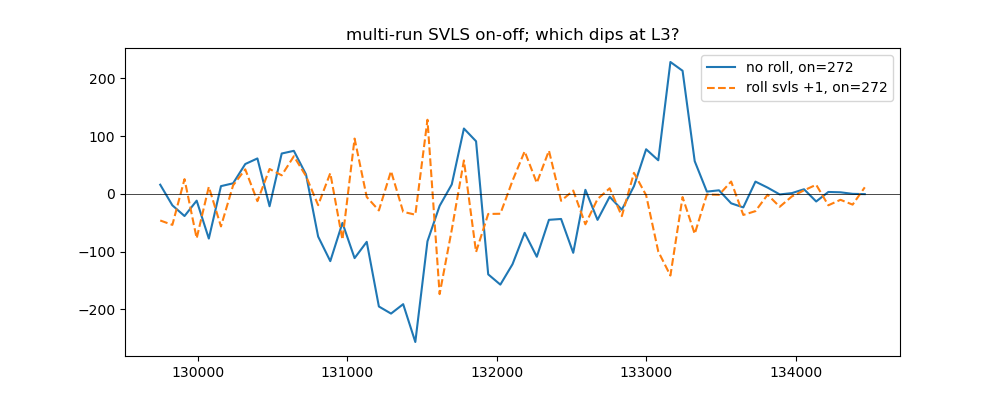

In [11]:
# C: bleach sign, accumulated over SAME-SHIFT runs to beat single-run noise
runs = [112,113,114]            # <-- use only runs sharing one calib row
PFY=[]; MONO=[]; ON=[]
for r in runs:
    fn = f'{base_folder}/{exp}/hdf5/smalldata/{exp}_Run{r:04d}.h5'
    with h5py.File(fn,'r') as f:
        c=f[f'{g}/count'][()].squeeze(); e=f[f'{g}/timing_sum_eventcodes'][()]
        s=f[f'{g}/droplet_dense_curve_corr_pj_ax_1_data'][()].astype(float)
        h=f[f'{g}/mono_hrencoder_sum_value'][()].squeeze()
    md=int(st.mode(c,keepdims=False)[0]); sf=np.where(c>0,c,1)
    PFY.append(np.nansum(s,1)); MONO.append(h/md); ON.append((e[:,272]/sf)>0.5)
PFY=np.concatenate(PFY); MONO=np.concatenate(MONO); ON=np.concatenate(ON)

edges=np.linspace(np.percentile(MONO,1),np.percentile(MONO,99),60); ctr=.5*(edges[:-1]+edges[1:])
def diff(v):
    son,_=np.histogram(MONO[ON],edges,weights=v[ON]); non,_=np.histogram(MONO[ON],edges)
    sof,_=np.histogram(MONO[~ON],edges,weights=v[~ON]); nof,_=np.histogram(MONO[~ON],edges) 
    return son/np.maximum(non,1)-sof/np.maximum(nof,1)
plt.figure(figsize=(10,4))
plt.plot(ctr, diff(PFY), label='no roll, on=272')
plt.plot(ctr, diff(np.roll(PFY,1)), '--', label='roll svls +1, on=272')
plt.axhline(0,color='k',lw=.5); plt.legend(); plt.title('multi-run SVLS on-off; which dips at L3?')

In [15]:
with h5py.File(fname,'r') as f:
    ts = f['intg/timestamp'][()].squeeze()
print('file already time-ordered?', np.all(np.diff(ts) >= 0))

idx    = np.argsort(ts)
pfy_s  = pfy[idx]; count_s = count[idx]; evc_s = evc[idx]
maj_s  = (evc_s[:,272] / np.where(count_s>0, count_s, 1)) > 0.5
print('TIME-ordered offset test (svls PFY contrast vs evc-272):')
for o in (-1, 0, 1):
    m = np.roll(maj_s, o)
    print(f'  {o:+d}: {np.nanmean(pfy_s[m]) - np.nanmean(pfy_s[~m]):+.3e}')

file already time-ordered? False
TIME-ordered offset test (svls PFY contrast vs evc-272):
  -1: +1.596e+01
  +0: -2.130e+01
  +1: -2.972e+01
